In [92]:
using CSV, DataFrames
using Plots
using LinearAlgebra

In [62]:
binder_df = CSV.read("simulation_results/binder_data.csv", DataFrame);

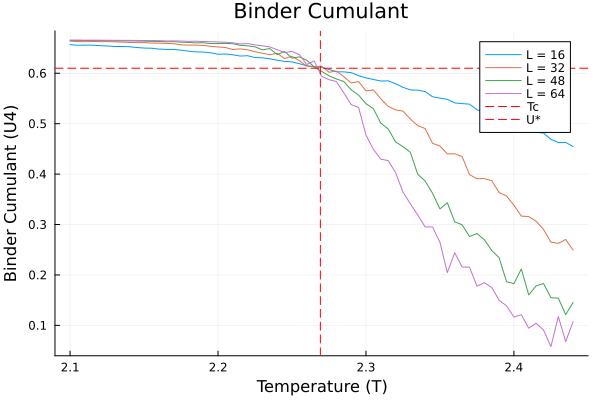

In [80]:
p = plot(
    title = "Binder Cumulant",
    xlabel = "Temperature (T)",
    ylabel = "Binder Cumulant (U4)",
    legend = :topright,
    linewidth = 8,
    grid = true
)

for L in [16, 32, 48, 64]
    df_L = binder_df[binder_df.L .== L, :]
    sort!(df_L, :T)

    plot!(p, df_L.T, df_L.U, label = "L = $L")
end

Tc = 2.269185

vline!(
    p,
    [Tc],
    label = "Tc",
    color = :red,
    linestyle = :dash,
    linewidth = 1
)

U_t = 0.61 #valor en que debería ocurrir el cruce

hline!(
    p,
    [U_t],
    label = "U*",
    color =:red,
    linestyle = :dash,
    linewidth = 1
)

p

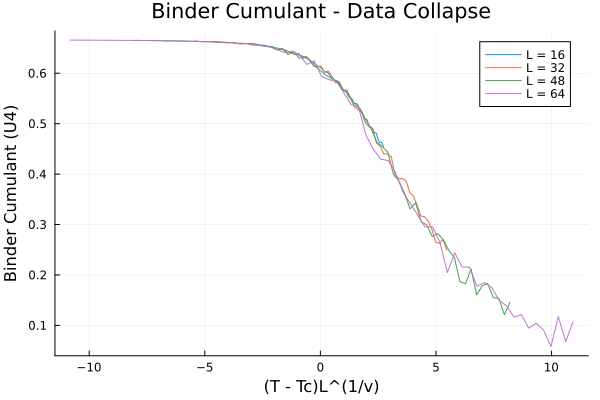

In [76]:
p = plot(
    title = "Binder Cumulant - Data Collapse",
    xlabel = "(T - Tc)L^(1/v)",
    ylabel = "Binder Cumulant (U4)",
    legend = :topright,
    linewidth = 2,
    grid = true,
)

nu = 1
Tc = 2.269185

for L in [16, 32, 48, 64]
    df_L = binder_df[binder_df.L .== L, :]
    sort!(df_L, :T)

    x = (df_L.T .- Tc) .* L^(1/nu)

    plot!(p, x, df_L.U, label = "L = $L")
end
p

Tenemos que
$$U_L(T)= f((T-T_c)L^{1/\nu})$$
luego, derivamos
$$\frac{\partial U}{\partial T}=L^{1/\nu}f'((T-T_c)L^{1/\nu})$$
Evaluamos en $T = T_c$
$$\left.\frac{\partial U}{\partial T}\right|_{T_c} \propto L^{1/\nu}$$
Finalmente tomando logaritmo
$$\log\left|\left.\frac{\partial U}{\partial T}\right|_{T_c}\right| \approx \frac{1}{\nu} \log(L)+C$$

Valor estimado de nu: 1.0081981513482101


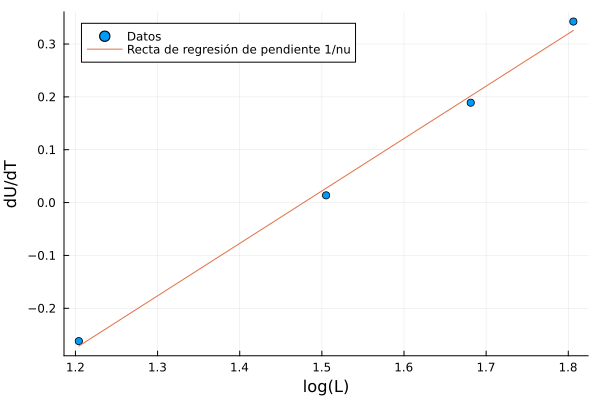

In [ ]:
b_Ls = []
Ls = [16, 32, 48, 64]

delta = 0.03
Tc = 2.269185

# Obtenemos la pendiente de la regresión para cada L, esta aproxima la derivada de U
for L in Ls
    filtered_df = binder_df[(binder_df.L .== L) .& (Tc - delta .<= binder_df.T .<= Tc + delta) , :]

    T = filtered_df.T
    U = filtered_df.U 

    X = hcat(ones(length(T)), T)
    a_L, b_L = X \ U
    push!(b_Ls, b_L)
end


ps = []

x = log10.(Ls)
y = log10.(abs.(b_Ls)) # dU/dT

X = hcat(ones(length(x)), x)
c, p = X \ y
nu_hat = 1 / p

println("Valor estimado de nu: ", nu_hat)

scatter(x, y, xlabel="log(L)", ylabel="dU/dT", label="Datos")
plot!(x, p .* x .+ c, label="Recta de regresión de pendiente 1/nu")
